In [1]:
'''все необходимые импорты'''

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score)

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Initial block

In [2]:
'''загрузка данных'''
data_dir = Path("data/raw")
if not data_dir.is_dir():
    data_dir = Path("../data/raw")

encounters = pd.read_csv(
    data_dir / "diabetic_data.csv",
    keep_default_na=False,
    na_values=["?"],
    dtype={
        "diag_1": "string",
        "diag_2": "string",
        "diag_3": "string",
        "payer_code": "string",
    },)

mapping_rows = pd.read_csv(
    data_dir / "IDS_mapping.csv",
    header=None,
    names=["code", "description"],
    dtype="string",
    keep_default_na=False,)

is_section_header = mapping_rows["description"].eq("description")
mapping_rows["field"] = mapping_rows["code"].where(is_section_header).ffill()

is_code = mapping_rows["code"].str.fullmatch(r"\d+")
id_mapping = mapping_rows.loc[is_code, ["field", "code", "description"]].copy()
id_mapping["code"] = id_mapping["code"].astype(int)

In [3]:
'''первичный обзор'''

assert encounters["encounter_id"].is_unique
assert set(encounters["readmitted"]) == {"<30", ">30", "NO"}
assert not id_mapping.duplicated(["field", "code"]).any()

'''смотрим на размеры выборки по госпитализациям'''
print(pd.Series({
    "Госпитализации": len(encounters),
    "Пациенты": encounters["patient_nbr"].nunique(),
    "Столбцы": encounters.shape[1]}, name="Количество").to_frame().to_string())

'''смотрим на профили стобцов'''
preview_columns = [
    "encounter_id", "patient_nbr", "age",
    "time_in_hospital", "discharge_disposition_id", "readmitted"]
print()
print(encounters[preview_columns].head().to_string())

column_profile = pd.DataFrame({
    "Тип": encounters.dtypes.astype(str),
    "Уникальных значений": encounters.nunique(),
    "Пропуски, %": (encounters.isna().mean() * 100).round(2)})


'''чекаем пропуски, и в какой процент по пропускам'''
print()
print(column_profile.sort_values("Пропуски, %", ascending=False).to_string())
print()
print(id_mapping.query("field == 'discharge_disposition_id'").head().to_string())

                Количество
Госпитализации      101766
Пациенты             71518
Столбцы                 50

   encounter_id  patient_nbr      age  time_in_hospital  discharge_disposition_id readmitted
0       2278392      8222157   [0-10)                 1                        25         NO
1        149190     55629189  [10-20)                 3                         1        >30
2         64410     86047875  [20-30)                 2                         1         NO
3        500364     82442376  [30-40)                 2                         1         NO
4         16680     42519267  [40-50)                 1                         1         NO

                             Тип  Уникальных значений  Пропуски, %
weight                       str                    9        96.86
medical_specialty            str                   72        49.08
payer_code                string                   17        39.56
race                         str                    5         2.

#### смотрим на исходы выписки

In [4]:
## Повторная госпитализация по исходу выписки
discharge_labels = (
    id_mapping.loc[id_mapping["field"].eq("discharge_disposition_id")]
    .set_index("code")["description"].rename("Исход выписки"))

target_order = ["<30", ">30", "NO"]
counts = pd.crosstab(
    encounters["discharge_disposition_id"],
    encounters["readmitted"]).reindex(columns=target_order, fill_value=0)

totals = counts.sum(axis=1)
shares = counts.div(totals, axis=0).mul(100).round(1).add_suffix(", %")

discharge_summary = (
    counts.assign(Всего=totals)
    .join(shares)
    .join(discharge_labels)
    .sort_values("Всего", ascending=False))

assert discharge_summary["Всего"].sum() == len(encounters)
discharge_summary[
    ["Исход выписки", "Всего", "<30", "<30, %", ">30", ">30, %", "NO", "NO, %"]]

,Исход выписки,Всего,<30,"<30, %",>30,">30, %",NO,"NO, %"
discharge_disposition_id,,,,,,,,
1,Discharged to home,60234,5602,9.3,21517,35.7,33115,55.0
3,Discharged/transferred to SNF,13954,2046,14.7,4916,35.2,6992,50.1
6,Discharged/transferred to home with home healt...,12902,1638,12.7,5362,41.6,5902,45.7
18,NULL,3691,459,12.4,1027,27.8,2205,59.7
2,Discharged/transferred to another short term h...,2128,342,16.1,668,31.4,1118,52.5
22,Discharged/transferred to another rehab fac in...,1993,552,27.7,519,26.0,922,46.3
11,Expired,1642,0,0.0,0,0.0,1642,100.0
5,Discharged/transferred to another type of inpa...,1184,247,20.9,350,29.6,587,49.6
25,Not Mapped,989,92,9.3,376,38.0,521,52.7


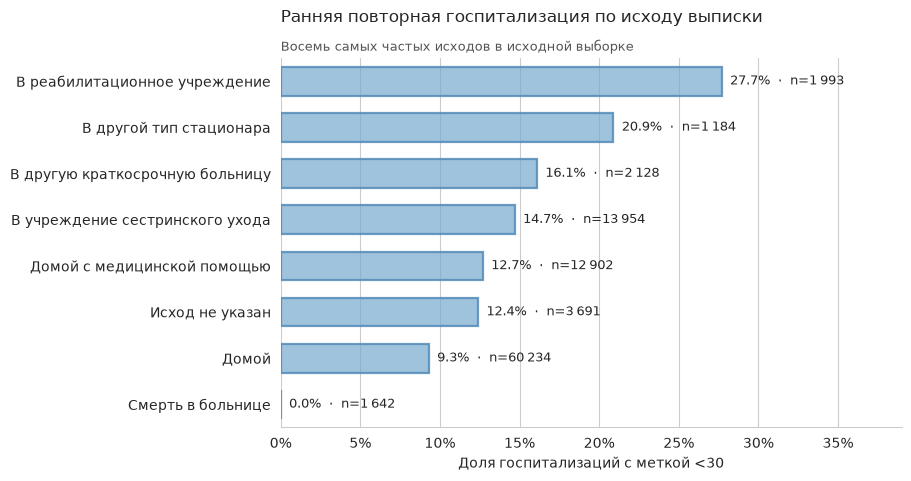

In [5]:
discharge_plot_labels = {
    1: "Домой",
    2: "В другую краткосрочную больницу",
    3: "В учреждение сестринского ухода",
    5: "В другой тип стационара",
    6: "Домой с медицинской помощью",
    11: "Смерть в больнице",
    18: "Исход не указан",
    22: "В реабилитационное учреждение",
}

discharge_plot = discharge_summary.head(8).sort_values("<30, %", ascending=False).copy()
discharge_plot["Группа"] = (
    discharge_plot.index.to_series().map(discharge_plot_labels)
    .fillna(discharge_plot["Исход выписки"])
)

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 4.7), layout="constrained")
    sns.barplot(
        data=discharge_plot, x="<30, %", y="Группа",
        color="#76A9CFB3", saturation=1, edgecolor="#538BB9D9",
        linewidth=1.6, width=0.62, ax=ax,
    )
    for bar in ax.containers[0]:
        bar.set_facecolor("#76A9CFB3")

    ax.bar_label(
        ax.containers[0],
        labels=[f"{rate:.1f}%  ·  n={total:,}".replace(",", " ")
                for rate, total in zip(discharge_plot["<30, %"], discharge_plot["Всего"])],
        padding=6,
        fontsize=9,
    )
    ax.set_xlim(0, 39)
    ax.set_xticks(range(0, 36, 5), labels=[f"{x}%" for x in range(0, 36, 5)])
    ax.set_title("Ранняя повторная госпитализация по исходу выписки", loc="left", pad=26)
    ax.text(0, 1.02, "Восемь самых частых исходов в исходной выборке",
            transform=ax.transAxes, color="#555555", fontsize=9)
    ax.set(xlabel="Доля госпитализаций с меткой <30", ylabel=None)
    sns.despine(ax=ax, left=True)

plt.show()

**Вывод:** Доля ранних повторных госпитализаций различается по исходам выписки: 9,3% при выписке домой и 27,7% при переводе на реабилитацию. Для прогноза при выписке живого пациента предлагаем исключить коды смерти и отдельно проверить, как на результаты влияет включение выписок в хоспис.

In [6]:
'''собираем рабочую выборку'''

death_codes = {11, 19, 20, 21}
cohort = encounters.loc[
    ~encounters["discharge_disposition_id"].isin(death_codes)].copy()
cohort["readmitted_30d"] = cohort["readmitted"].eq("<30").astype(int)

print(pd.Series({
    "Госпитализации": f"{len(cohort):,}",
    "Пациенты": f"{cohort['patient_nbr'].nunique():,}",
    "Доля ранних повторных госпитализаций": f"{cohort['readmitted_30d'].mean():.2%}"
}).to_frame("Рабочая выборка").to_string())

                                     Рабочая выборка
Госпитализации                               100,114
Пациенты                                      70,439
Доля ранних повторных госпитализаций          11.34%


#### смотрим сколько госпитализаций приходится на пациента

пациенты с несколькими записями: 23.4%
доля строк этих пациентов: 46.1%


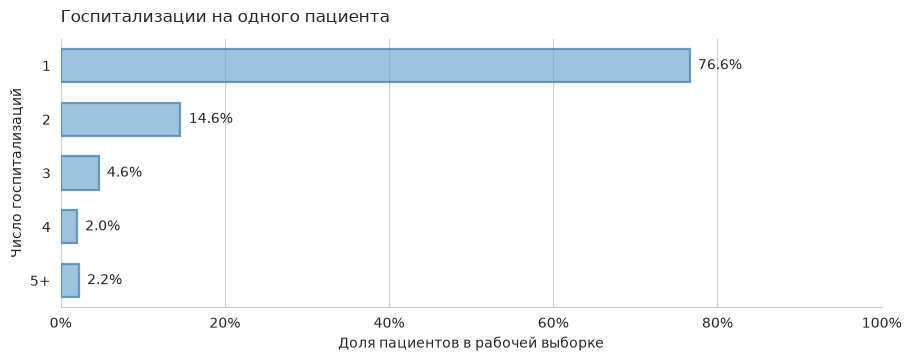

In [7]:
encounters_per_patient = cohort.groupby("patient_nbr").size()
repeat_patients = encounters_per_patient.gt(1)

print(f"пациенты с несколькими записями: {repeat_patients.mean():.1%}")
print(f"доля строк этих пациентов: {encounters_per_patient[repeat_patients].sum() / len(cohort):.1%}")

patient_counts = (
    encounters_per_patient.clip(upper=5)
    .value_counts().reindex(range(1, 6), fill_value=0))

patient_distribution = pd.DataFrame({
    "Госпитализаций": ["1", "2", "3", "4", "5+"],
    "Доля, %": patient_counts.to_numpy() / patient_counts.sum() * 100,
})

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
    sns.barplot(
        data=patient_distribution, x="Доля, %", y="Госпитализаций",
        color="#76A9CFB3", saturation=1, edgecolor="#538BB9D9",
        linewidth=1.6, width=0.62, ax=ax,
    )
    for bar in ax.containers[0]:
        bar.set_facecolor("#76A9CFB3")

    ax.bar_label(
        ax.containers[0],
        labels=[f"{share:.1f}%" for share in patient_distribution["Доля, %"]],
        padding=6,
    )
    ax.set_xlim(0, 100)
    ax.set_xticks(range(0, 101, 20), labels=[f"{x}%" for x in range(0, 101, 20)])
    ax.set_title("Госпитализации на одного пациента", loc="left", pad=12)
    ax.set(xlabel="Доля пациентов в рабочей выборке", ylabel="Число госпитализаций")
    sns.despine(ax=ax, left=True)

plt.show()

## детально смотрим на данные

#### Разбиение по пациентам

In [8]:
groups = cohort["patient_nbr"]
train_idx, holdout_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42).split(cohort, groups=groups)
)
train = cohort.iloc[train_idx].copy()
holdout = cohort.iloc[holdout_idx]
val_idx, test_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
    .split(holdout, groups=holdout["patient_nbr"])
)
validation = holdout.iloc[val_idx].copy()
test = holdout.iloc[test_idx].copy()

splits = {"Train": train, "Validation": validation, "Test": test}
assert sum(part["patient_nbr"].nunique() for part in splits.values()) == groups.nunique()
assert sum(len(part) for part in splits.values()) == len(cohort)

split_summary = pd.DataFrame({
    name: {
        "Пациенты": part["patient_nbr"].nunique(),
        "Госпитализации": len(part),
        "Доля <30, %": 100 * part["readmitted_30d"].mean(),
    }
    for name, part in splits.items()
}).T
print(split_summary.to_string(formatters={
    "Пациенты": "{:,.0f}".format, "Госпитализации": "{:,.0f}".format,
    "Доля <30, %": "{:.2f}".format,
}))

           Пациенты Госпитализации Доля <30, %
Train        49,307         69,944       11.30
Validation   10,566         15,172       11.52
Test         10,566         14,998       11.35


#### История обращений за предыдущий год

Гипотеза: доля ранних повторных госпитализаций выше у пациентов с предыдущими стационарными обращениями. Посмотрим, где возникает разница и насколько она зависит от пациентов с несколькими записями.

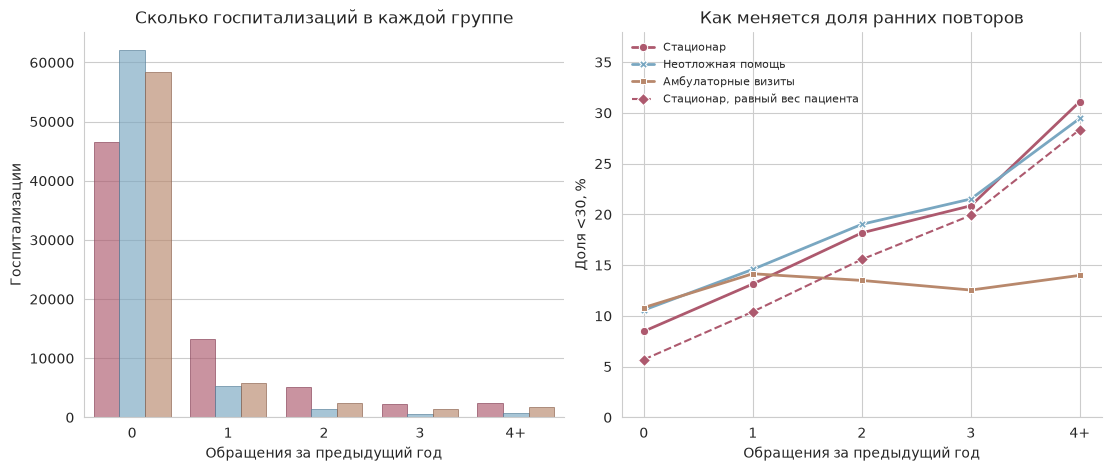

                      n  rate weighted_rate
number_inpatient                           
0                46,611  8.5%          5.7%
1                13,332 13.1%         10.4%
2                 5,187 18.2%         15.6%
3                 2,307 20.8%         19.9%
4+                2,507 31.1%         28.4%


In [9]:
visit_labels = {
    "number_inpatient": "Стационар",
    "number_emergency": "Неотложная помощь",
    "number_outpatient": "Амбулаторные визиты",
}
visit_order = ["0", "1", "2", "3", "4+"]
patient_weight = 1 / train.groupby("patient_nbr")["patient_nbr"].transform("size")
visit_summary = {}


for column, title in visit_labels.items():
    visits = train[column].clip(upper=4).astype(str).replace("4", "4+")
    report = train["readmitted_30d"].groupby(visits).agg(n="size", rate="mean")
    report["weighted_rate"] = (
        (train["readmitted_30d"] * patient_weight).groupby(visits).sum()
        / patient_weight.groupby(visits).sum()
    )
    visit_summary[column] = report.reindex(visit_order)

visit_plot = pd.concat(
    {visit_labels[column]: report for column, report in visit_summary.items()},
    names=["Вид обращения", "Обращения"],
).reset_index()
visit_plot["Доля <30, %"] = visit_plot["rate"] * 100
visit_colors = {
    "Стационар": "#AD596E", "Неотложная помощь": "#79A7C1",
    "Амбулаторные визиты": "#B8886C",
}
inpatient = visit_summary["number_inpatient"]

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, (volume_ax, rate_ax) = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
    sns.barplot(
        data=visit_plot, x="Обращения", y="n", hue="Вид обращения",
        order=visit_order, hue_order=list(visit_colors), palette=visit_colors, alpha=0.65, saturation=1,
        linewidth=0.7, legend=False, ax=volume_ax,
    )
    for container, edge in zip(volume_ax.containers, ["#864056", "#567E99", "#8B624D"], strict=True):
        for bar in container:
            bar.set_edgecolor(edge)
    sns.lineplot(
        data=visit_plot, x="Обращения", y="Доля <30, %",
        hue="Вид обращения", style="Вид обращения", palette=visit_colors,
        markers=True, dashes=False, linewidth=2, ax=rate_ax,
    )
    sns.lineplot(x=visit_order, y=inpatient["weighted_rate"] * 100, color=visit_colors["Стационар"],
                 linestyle="--", marker="D", label="Стационар, равный вес пациента", ax=rate_ax)
    rate_ax.legend(title=None, loc="upper left", fontsize=8, frameon=False)
    volume_ax.set(title="Сколько госпитализаций в каждой группе", ylabel="Госпитализации")
    rate_ax.set(title="Как меняется доля ранних повторов", ylabel="Доля <30, %", ylim=(0, 38))
    for ax in (volume_ax, rate_ax):
        ax.set_xlabel("Обращения за предыдущий год")
    sns.despine(fig=fig)
plt.show()

print(inpatient.to_string(formatters={"n": "{:,}".format, "rate": "{:.1%}".format,
                                     "weighted_rate": "{:.1%}".format}))

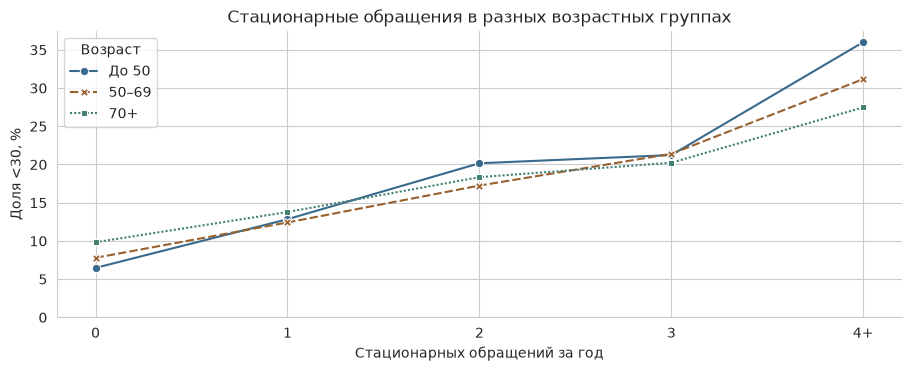

Обращения      0     1     2     3   4+
Возраст                                
До 50       7523  1760   734   405  647
50–69      18610  5041  1972   874  972
70+        20478  6531  2481  1028  888


In [10]:
age_start = train["age"].str.extract(r"^\[(\d+)", expand=False).astype(int)
age_band = pd.cut(age_start, bins=[-1, 49, 69, 100], labels=["До 50", "50–69", "70+"])
inpatient_visits = train["number_inpatient"].clip(upper=4)
age_history = train["readmitted_30d"].groupby([
    age_band.rename("Возраст"), inpatient_visits.rename("Обращения"),
], observed=True).agg(n="size", rate="mean").reset_index()
age_history["Доля <30, %"] = age_history["rate"] * 100

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
    sns.lineplot(
        data=age_history, x="Обращения", y="Доля <30, %",
        hue="Возраст", style="Возраст", markers=True,
        palette=["#386A8C", "#98612E", "#438074"], ax=ax,
    )
    ax.set_xticks(range(5), visit_order)
    ax.set(
        title="Стационарные обращения в разных возрастных группах",
        xlabel="Стационарных обращений за год", ylim=(0, None),
    )
    sns.despine(ax=ax)
plt.show()

print(age_history.pivot(index="Возраст", columns="Обращения", values="n").rename(columns={4: "4+"}).to_string())

**Вывод.** При 0 прошлых стационарных обращений доля `<30` составляет 8,5%, при 4 и более — 31,1%. С равным суммарным весом пациентов рост сохраняется (5,7–28,4%). Для амбулаторных визитов монотонного роста по этим группам не видно. Рост от 0 до 4 и более обращений виден во всех трёх возрастных группах.

#### Пропуски и измерение HbA1c

Отдельно сравниваем пропуски и категорию `None` в `A1Cresult`. Она означает, что HbA1c не измеряли.

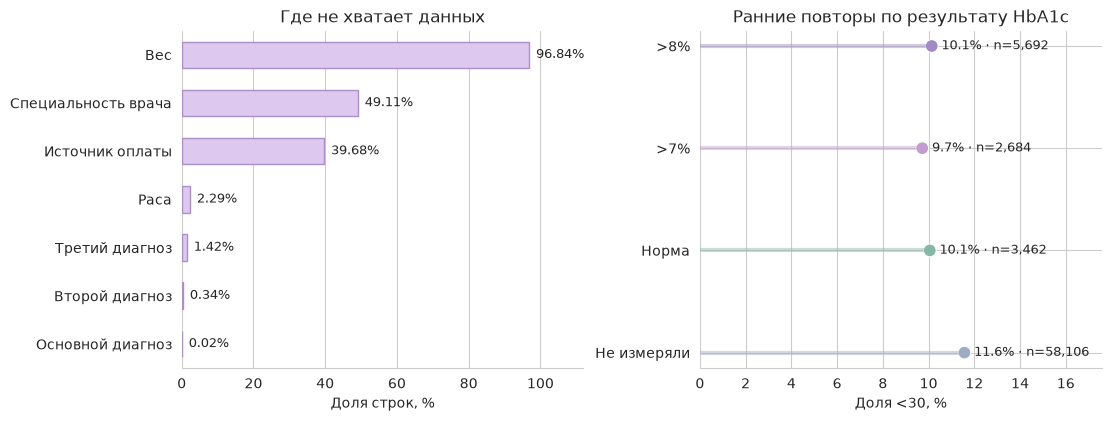

HbA1c измеряли в 16.9% госпитализаций на train.
                    n   rate
HbA1c измеряли              
False          58,106 11.57%
True           11,838 10.02%


In [11]:
missing_pct = (train.isna().mean() * 100).loc[lambda values: values > 0].sort_values(ascending=False)
a1c_order = ["None", "Norm", ">7", ">8"]
a1c_summary = (
    train.groupby("A1Cresult")["readmitted_30d"].agg(n="size", rate="mean").reindex(a1c_order)
)
measured = train["A1Cresult"].ne("None")
a1c_comparison = train.groupby(measured.rename("HbA1c измеряли"))["readmitted_30d"].agg(n="size", rate="mean")


field_labels = {
    "weight": "Вес", "medical_specialty": "Специальность врача",
    "payer_code": "Источник оплаты", "race": "Раса",
    "diag_1": "Основной диагноз", "diag_2": "Второй диагноз", "diag_3": "Третий диагноз",
}
result_labels = ["Не измеряли", "Норма", ">7%", ">8%"]
result_colors = ["#9EACC2", "#87B7A8", "#C39DD0", "#A18AC5"]

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, (missing_ax, result_ax) = plt.subplots(1, 2, figsize=(11, 4.1), layout="constrained")
    sns.barplot(x=missing_pct, y=missing_pct.index.map(lambda field: field_labels.get(field, field)),
                color="#DDC9EF", saturation=1, edgecolor="#AA90C4", width=0.55, ax=missing_ax)
    missing_ax.bar_label(missing_ax.containers[0], fmt="%.2f%%", padding=5, fontsize=9)
    missing_ax.set(title="Где не хватает данных", xlabel="Доля строк, %", ylabel=None, xlim=(0, 112))

    rates = a1c_summary["rate"].to_numpy() * 100
    result_ax.hlines(result_labels, 0, rates, colors=result_colors, alpha=0.45, linewidth=3)
    sns.scatterplot(x=rates, y=result_labels, hue=result_labels, palette=result_colors,
                    legend=False, s=85, edgecolor="white", linewidth=0.8, ax=result_ax)
    for i, (n, rate) in enumerate(a1c_summary.itertuples(index=False)):
        result_ax.annotate(f"{rate:.1%} · n={n:,}", (rate * 100, i),
                           xytext=(7, 0), textcoords="offset points", va="center", fontsize=9)
    result_ax.invert_yaxis()
    result_ax.set(title="Ранние повторы по результату HbA1c", xlabel="Доля <30, %",
                  ylabel=None, xlim=(0, max(rates) + 6))
    sns.despine(fig=fig, left=True)
plt.show()

print(f"HbA1c измеряли в {measured.mean():.1%} госпитализаций на train.")
print(a1c_comparison.to_string(formatters={"n": "{:,}".format, "rate": "{:.2%}".format}))

**Вывод.** HbA1c измеряли в 16,9% госпитализаций на train. Доля `<30` составила 10,0% при измерении и 11,6% при его отсутствии. Направление различия совпадает с результатом статьи 2014 года, где выборку формировали по другим правилам. [Strack et al., 2014](https://pmc.ncbi.nlm.nih.gov/articles/PMC3996476/)

#### Диагнозы по группам ICD-9

Сравниваем размер группы и долю `<30` по основному диагнозу. Для проверки охвата таблица показывает, как часто те же группы встречаются среди вторичных диагнозов.

In [12]:
diagnosis_columns = ["diag_1", "diag_2", "diag_3"]
chapter_labels = [
    "Инфекции", "Новообразования", "Эндокринные и обменные", "Болезни крови",
    "Психические расстройства", "Нервная система и органы чувств", "Кровообращение",
    "Дыхательная система", "Пищеварительная система", "Мочеполовая система",
    "Беременность и роды", "Кожа", "Опорно-двигательная система",
    "Врождённые аномалии", "Перинатальный период", "Симптомы и признаки", "Травмы и отравления",
]

def diagnosis_group(codes):
    prefix = pd.to_numeric(codes.str.extract(r"^(\d{3})", expand=False), errors="coerce")
    groups = pd.cut(
        prefix,
        bins=[0, 139, 239, 279, 289, 319, 389, 459, 519, 579, 629, 679, 709, 739, 759, 779, 799, 999],
        labels=chapter_labels,
    ).astype("string")
    groups = groups.mask(prefix.eq(250).fillna(False), "Диабет (250.xx)")
    groups = groups.mask(codes.str.startswith(("E", "V"), na=False), "Коды E и V")
    return groups.mask(codes.isna(), "Пропуск").fillna("Прочее")

diagnosis_groups = train[diagnosis_columns].apply(diagnosis_group)
assert diagnosis_group(pd.Series(["250.83", "042", "V45", pd.NA], dtype="string")).tolist() == [
    "Диабет (250.xx)", "Инфекции", "Коды E и V", "Пропуск",
]
diagnosis_coverage = diagnosis_groups.apply(pd.Series.value_counts).fillna(0).astype(int)
print(diagnosis_coverage.sort_values("diag_1", ascending=False).to_string())

primary = pd.DataFrame({
    "Группа": diagnosis_groups["diag_1"],
    "Код": train["diag_1"],
    "Ранняя госпитализация": train["readmitted_30d"],
})
diagnosis_summary = primary.groupby("Группа")["Ранняя госпитализация"].agg(
    Госпитализации="size", Ранние="sum", Доля="mean",
)
diagnosis_summary["Частые коды"] = primary.groupby("Группа")["Код"].agg(
    lambda codes: ", ".join(codes.value_counts().head(3).index) or "—"
)
diagnosis_summary["Доля, %"] = diagnosis_summary["Доля"] * 100

diagnosis_summary["Логарифм размера"] = np.log10(diagnosis_summary["Госпитализации"])
size_ticks = [1, 10, 100, 1_000, 10_000]

fig = px.scatter(
    diagnosis_summary.reset_index(), x="Госпитализации", y="Доля, %",
    hover_name="Группа", hover_data={"Ранние": True, "Частые коды": True, "Доля, %": ":.1f", "Логарифм размера": False},
    color="Логарифм размера",
    color_continuous_scale=["#F5DCE3", "#DC9BAD", "#B96279", "#7C2D45"],
    log_x=True, template="plotly_white",
    title="Основной диагноз и ранняя повторная госпитализация",
    labels={"Госпитализации": "Госпитализации в группе (лог. шкала)", "Доля, %": "Доля <30, %"},
)
visible_size_ticks = [size for size in size_ticks
                      if diagnosis_summary["Госпитализации"].min() <= size <= diagnosis_summary["Госпитализации"].max()]
fig.update_coloraxes(colorbar={
    "title": "Госпитализации", "tickvals": np.log10(visible_size_ticks),
    "ticktext": [f"{size:,}".replace(",", " ") for size in visible_size_ticks],
})
fig.update_traces(marker={"size": 12, "line": {"color": "#78374B", "width": 1.1}})
fig.show(renderer="plotly_mimetype")

                                 diag_1  diag_2  diag_3
Кровообращение                    20782   21672   20569
Дыхательная система                7073    6847    4594
Пищеварительная система            6359    2734    2430
Диабет (250.xx)                    6005    8959   11770
Симптомы и признаки                5315    3197    3124
Травмы и отравления                4813    1616    1333
Мочеполовая система                3455    5484    4313
Опорно-двигательная система        3450    1227    1358
Новообразования                    2316    1724    1214
Эндокринные и обменные             1851    5629    6328
Кожа                               1791    2471    1707
Прочее                             1709    1047    1047
Психические расстройства           1564    1859    2171
Коды E и V                         1197    1748    3542
Нервная система и органы чувств     841     826    1195
Болезни крови                       780    2026    1722
Беременность и роды                 501     315 

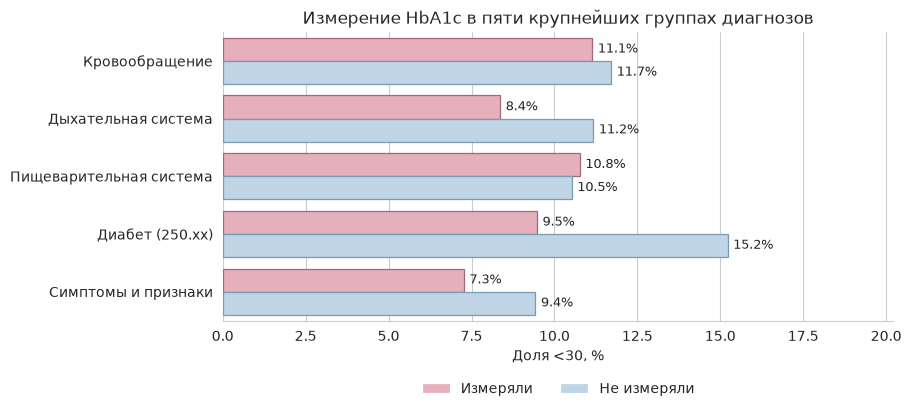

Измерение                Измеряли  Не измеряли
Группа                                        
Диабет (250.xx)              1879         4126
Дыхательная система          1148         5925
Кровообращение               3671        17111
Пищеварительная система       771         5588
Симптомы и признаки          1018         4297


In [13]:
common_diagnoses = diagnosis_summary.nlargest(5, "Госпитализации").index
a1c_by_diagnosis = (
    primary.assign(Измерение=measured.map({True: "Измеряли", False: "Не измеряли"}))
    .loc[primary["Группа"].isin(common_diagnoses)]
    .groupby(["Группа", "Измерение"])["Ранняя госпитализация"].agg(n="size", rate="mean")
)
a1c_pairs = a1c_by_diagnosis.reset_index()
a1c_pairs["Доля <30, %"] = a1c_pairs["rate"] * 100

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    sns.barplot(
        data=a1c_pairs, x="Доля <30, %", y="Группа", hue="Измерение",
        order=common_diagnoses, hue_order=["Измеряли", "Не измеряли"], saturation=1,
        palette=["#E5B0BC", "#BFD4E5"], linewidth=0.9, ax=ax,
    )
    for container, edge in zip(ax.containers, ["#A56778", "#789AB4"], strict=True):
        for bar in container:
            bar.set_edgecolor(edge)
        ax.bar_label(container, fmt="%.1f%%", padding=4, fontsize=9)
    ax.set(
        title="Измерение HbA1c в пяти крупнейших группах диагнозов",
        ylabel=None, xlim=(0, a1c_pairs["Доля <30, %"].max() + 5),
    )
    ax.legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
    sns.despine(ax=ax, left=True)
plt.show()

print(a1c_by_diagnosis["n"].unstack().to_string())

**Вывод.** Для основного диагноза «Диабет» доля `<30` составила 9,5% при измерении HbA1c и 15,2% при его отсутствии. В группе болезней пищеварительной системы доли близки (10,8% и 10,5%). Такое сравнение описывает различия в данных и не оценивает эффект измерения.

#### Длительность госпитализации и объём помощи

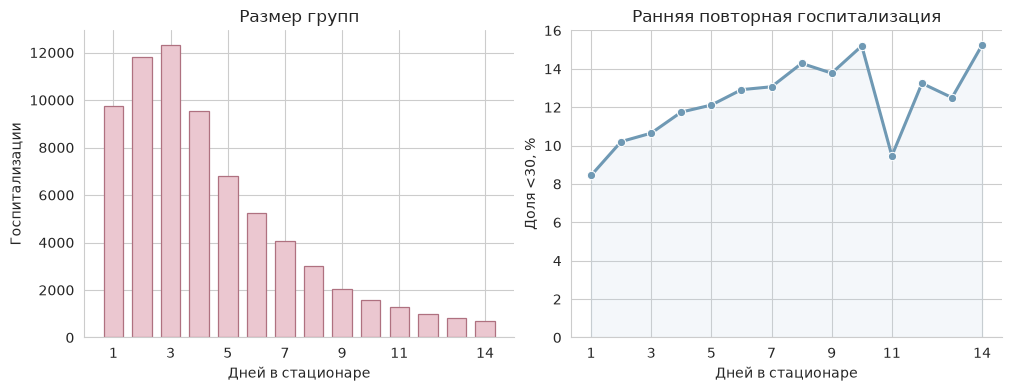

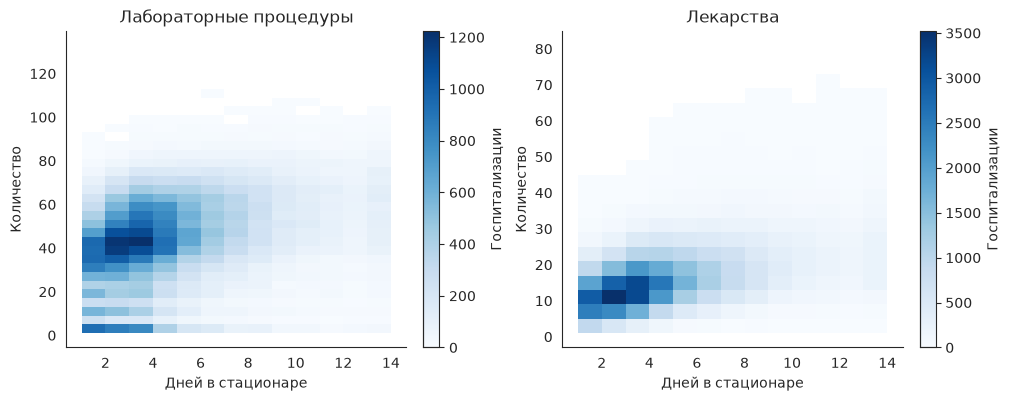

In [14]:
stay_summary = train.groupby("time_in_hospital")["readmitted_30d"].agg(n="size", rate="mean")

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, (volume_ax, rate_ax) = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
    days = stay_summary.index
    rates = stay_summary["rate"] * 100
    volume_ax.bar(days, stay_summary["n"], width=0.68, color="#EBC7D0",
                  edgecolor="#AF7180", linewidth=0.9)
    sns.lineplot(x=days, y=rates, color="#6F99B4", marker="o", linewidth=2.2, ax=rate_ax)
    rate_ax.fill_between(days, 0, rates, color="#BED5E5", alpha=0.17)
    volume_ax.set(title="Размер групп", ylabel="Госпитализации")
    rate_ax.set(title="Ранняя повторная госпитализация", ylabel="Доля <30, %", ylim=(0, None))
    for ax in (volume_ax, rate_ax):
        ax.set(xlabel="Дней в стационаре", xticks=[1, 3, 5, 7, 9, 11, 14])
    sns.despine(fig=fig)
plt.show()

with sns.axes_style("white"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), layout="constrained")
    for ax, column, label in zip(
        axes, ["num_lab_procedures", "num_medications"], ["Лабораторные процедуры", "Лекарства"]
    ):
        sns.histplot(
            data=train, x="time_in_hospital", y=column, binwidth=(1, 4), pthresh=0,
            cmap="Blues", cbar=True, cbar_kws={"label": "Госпитализации"}, ax=ax,
        )
        ax.set(title=label, xlabel="Дней в стационаре", ylabel="Количество")
    sns.despine(fig=fig)
plt.show()

**Вывод.** Доля `<30` растёт с 8,4% при однодневной госпитализации до 14,3% при восьмидневной. Для более длинных госпитализаций группы меньше, а доли колеблются. На двумерных гистограммах видно, что число анализов и лекарств стоит рассматривать вместе с длительностью пребывания.

#### Необычные госпитализации

Сопоставляем по 1% строк, отмеченных двумя способами. Правило по квантилям ранжирует строки по максимальному относительному выходу за интервал от 1-го до 99-го процентиля. Isolation Forest использует совместные значения тех же признаков. Метка `<30` используется только для описания групп.

                             n  rate
Группа                              
Оба метода                 324 29.9%
Остальные               68,870 11.1%
Только Isolation Forest    375 25.6%
Только квантили            375 22.4%


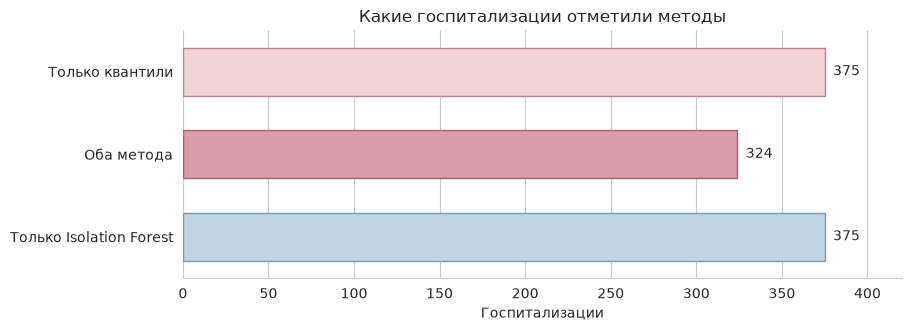

,encounter_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_inpatient,number_emergency,number_outpatient,Группа,Квантили,Isolation_Forest
88079,282476916,1,1,0,11,2,64,2,Оба метода,15.00,0.652
88897,286546980,4,30,3,18,3,63,2,Оба метода,14.75,0.668
83844,263161812,2,36,0,14,2,76,2,Только квантили,18.00,0.623
32601,103784028,6,19,2,14,0,0,35,Только квантили,6.00,0.622
87989,281962326,12,76,6,35,6,2,5,Только Isolation Forest,0.00,0.737
86533,275206122,8,72,3,37,5,6,4,Только Isolation Forest,0.50,0.718


In [15]:
anomaly_columns = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_inpatient", "number_emergency", "number_outpatient",
]
anomaly_features = train[anomaly_columns]
low, high = anomaly_features.quantile(0.01), anomaly_features.quantile(0.99)
span = (high - low).clip(lower=1)
quantile_score = pd.concat([
    (low - anomaly_features).div(span),
    (anomaly_features - high).div(span),
], axis=1).max(axis=1).clip(lower=0)

forest = IsolationForest(n_estimators=150, random_state=42, n_jobs=-1)
forest.fit(anomaly_features)
forest_score = pd.Series(-forest.score_samples(anomaly_features), index=train.index)

n_flagged = round(0.01 * len(train))
tie_order = train.sample(frac=1, random_state=42).index
by_quantile = train.index.isin(quantile_score.reindex(tie_order).nlargest(n_flagged).index)
by_forest = train.index.isin(forest_score.reindex(tie_order).nlargest(n_flagged).index)
assert by_quantile.sum() == by_forest.sum() == n_flagged
assert (quantile_score > 0).sum() >= n_flagged

anomaly_group = pd.Series(np.select(
    [by_quantile & by_forest, by_quantile, by_forest],
    ["Оба метода", "Только квантили", "Только Isolation Forest"], default="Остальные",
), index=train.index, name="Группа")
anomaly_summary = train.groupby(anomaly_group)["readmitted_30d"].agg(n="size", rate="mean")
print(anomaly_summary.to_string(formatters={"n": "{:,}".format, "rate": "{:.1%}".format}))

flag_order = ["Только квантили", "Оба метода", "Только Isolation Forest"]
flagged = anomaly_summary.loc[flag_order].reset_index()
method_colors = dict(zip(flag_order, ["#F0D2D9", "#D99CAC", "#BFD4E5"]))
with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 3.2), layout="constrained")
    sns.barplot(data=flagged, x="n", y="Группа", hue="Группа", hue_order=flag_order, palette=method_colors,
                legend=False, saturation=1, linewidth=1, width=0.58, ax=ax)
    for container, edge in zip(ax.containers, ["#B78491", "#A66275", "#789AB4"], strict=True):
        for bar in container:
            bar.set_edgecolor(edge)
        ax.bar_label(container, padding=6)
    ax.margins(x=0.12)
    ax.set(title="Какие госпитализации отметили методы", xlabel="Госпитализации", ylabel=None)
    sns.despine(ax=ax, left=True)
plt.show()

examples = train[["encounter_id", *anomaly_columns]].assign(
    Группа=anomaly_group, Квантили=quantile_score.round(3), Isolation_Forest=forest_score.round(3)
)
examples = examples.loc[examples["Группа"].ne("Остальные")]
pd.concat([
    examples.loc[examples["Группа"].eq(group)].nlargest(2, score)
    for group, score in (
        ("Оба метода", "Квантили"), ("Только квантили", "Квантили"),
        ("Только Isolation Forest", "Isolation_Forest"),
    )
])

**Вывод.** Каждый метод отметил 699 госпитализаций, из которых совпали 324. Доля `<30` в пересечении — 29,9%, среди остальных неотмеченных строк — 11,1%. Поскольку отмеченные случаи включают заметную долю ранних повторных госпитализаций, влияние их исключения проверим отдельным экспериментом на общей валидации.